In [134]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [135]:
from sklearn.datasets import load_iris

In [136]:
iris = load_iris()

In [137]:
X=iris.data
y=iris.target

In [138]:
feature_names = iris.feature_names
class_names = iris.target_names

In [139]:
X.shape

(150, 4)

In [140]:
class_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [141]:
df=pd.DataFrame(X,columns=feature_names)


In [142]:
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [143]:
df.shape

(150, 4)

In [144]:
df.tail()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3
149,5.9,3.0,5.1,1.8


In [145]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [146]:
df["species"]=[class_names[i] for i in y]

In [147]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [148]:
df[feature_names].describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


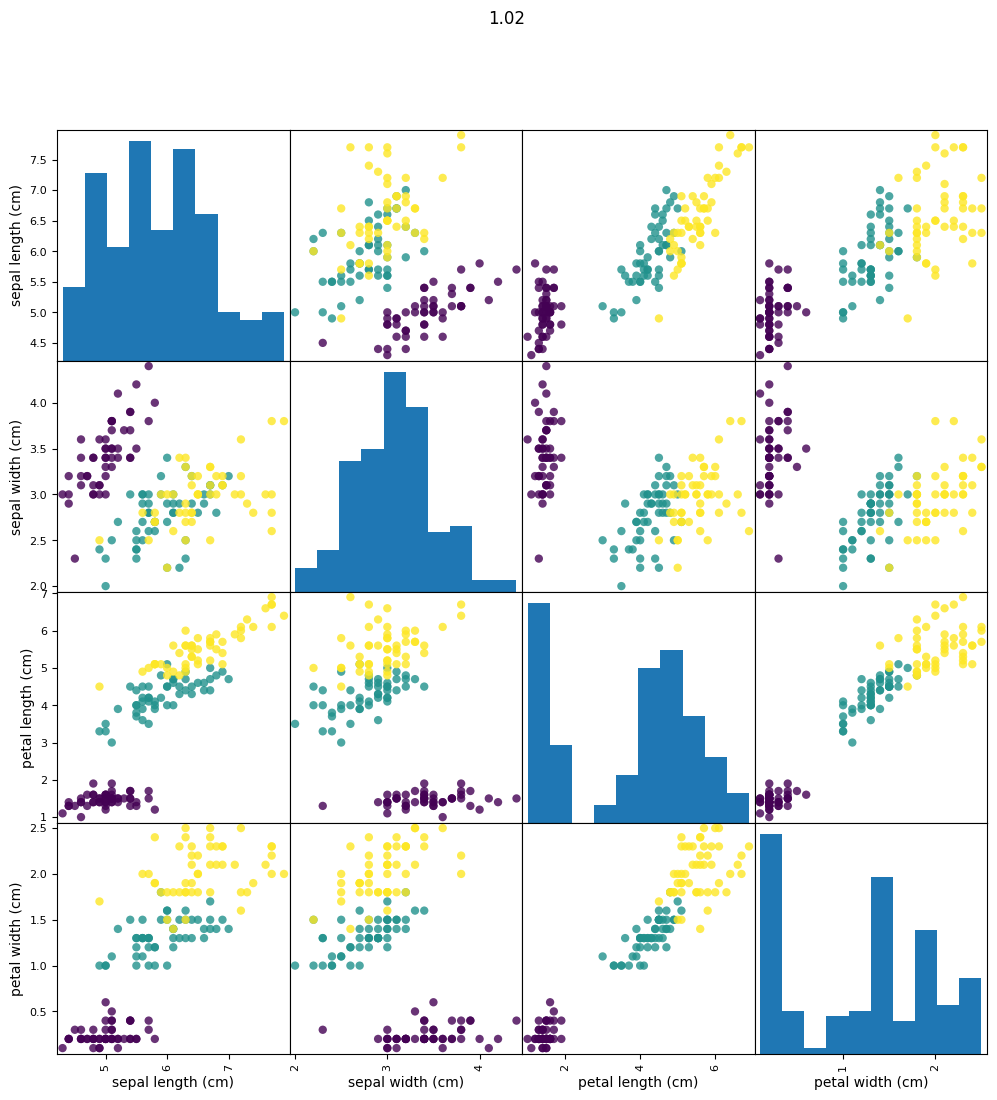

In [149]:
pd.plotting.scatter_matrix(df[feature_names],figsize=(12,12),diagonal="hist",c=y,alpha=0.8,marker="o")
plt.suptitle(t=1.02)
plt.show()

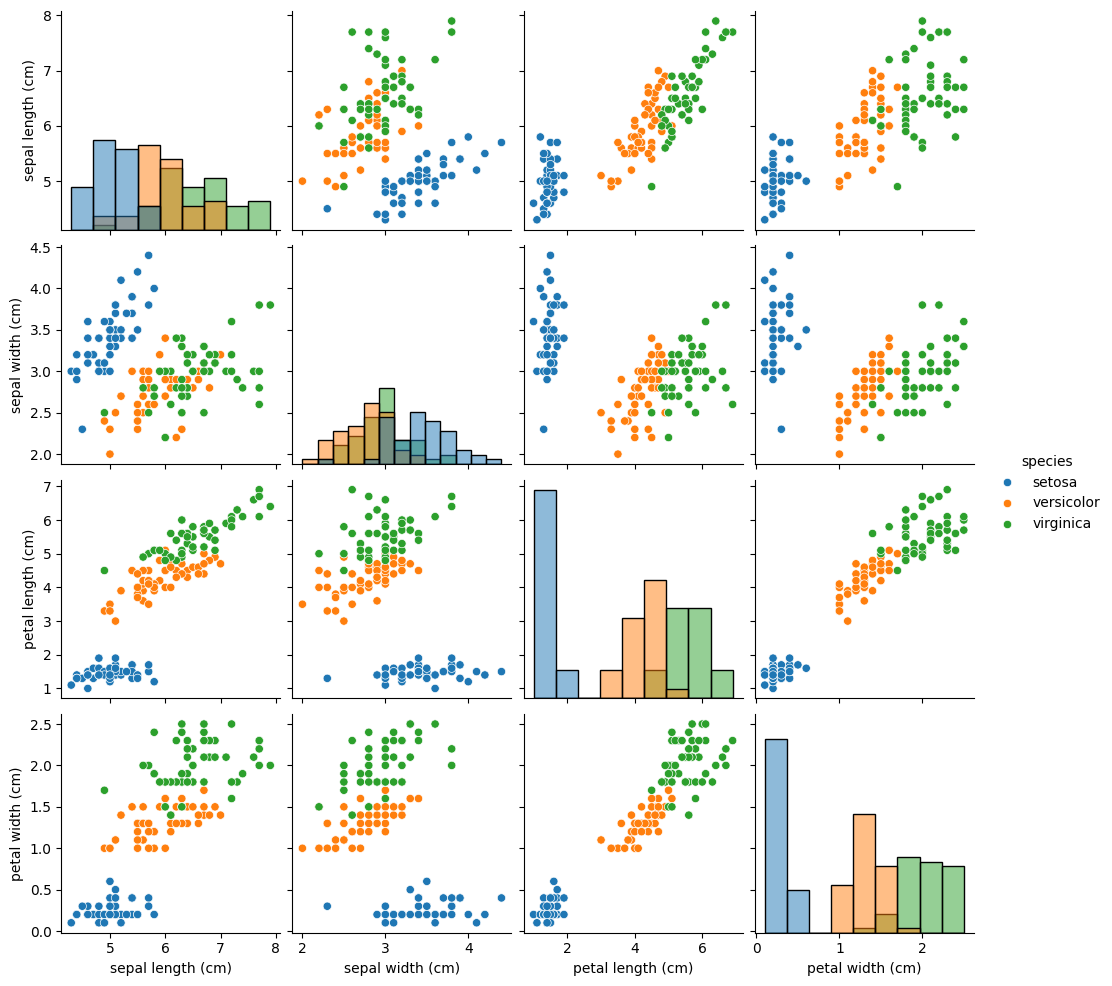

In [150]:
import seaborn as sns
sns.pairplot(df,hue="species",diag_kind="hist",height=2.5)

In [151]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

In [152]:
def entropy(y):
    if len(y)==0:
        return 0
    _,counts=np.unique(y,return_counts=True)
    probability=counts/len(y)
    return -np.sum(probability*np.log2(probability))


In [153]:
def gini(y):
    if len(y)==0:
        return 0
    _,counts=np.unique(y,return_counts=True)
    probability=counts/len(y)
    return 1-np.sum(probability**2)

    

In [154]:
print(entropy(y))

1.584962500721156


In [155]:
print(gini(y))

0.6666666666666667


In [156]:
left=y[X[:,2]<=2.45]
right=y[X[:,2]>2.45]


In [157]:
print(entropy(left))



-0.0


In [158]:
print(gini(left))

0.0


In [159]:
print(entropy(right))


1.0


In [160]:
print(gini(right))

0.5


In [161]:
weight_entropy=((len(left)/len(y))*entropy(left)+(len(right)/len(y))*entropy(right))

In [162]:
IG=entropy(y)-weight_entropy

In [163]:
print(weight_entropy)

0.6666666666666666


In [164]:
print(IG)

0.9182958340544894


The split at petal len 2.45 seprate the setosa from the rem iris species the left only contains setosa so it's entropy and gini are 0 the right contains versicolor and virginica 
The IG is approx 0.918 bits that indicates the reduction in entrop 

In [165]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [166]:
dt=DecisionTreeClassifier(max_depth=2,criterion="entropy",random_state=42)

In [167]:
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [168]:
y_pred_dt = dt.predict(X_test)

In [169]:
from sklearn.metrics import accuracy_score

In [170]:
print(accuracy_score(y_train, dt.predict(X_train)))

0.95


In [171]:
print(accuracy_score(y_test,y_pred_dt))

0.9666666666666667


In [172]:
dt=DecisionTreeClassifier(max_depth=3,criterion="entropy",random_state=42)

In [173]:
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [174]:
y_pred_dt = dt.predict(X_test)

In [175]:
print(accuracy_score(y_train, dt.predict(X_train)))

0.9583333333333334


In [176]:
print(accuracy_score(y_test,y_pred_dt))

1.0


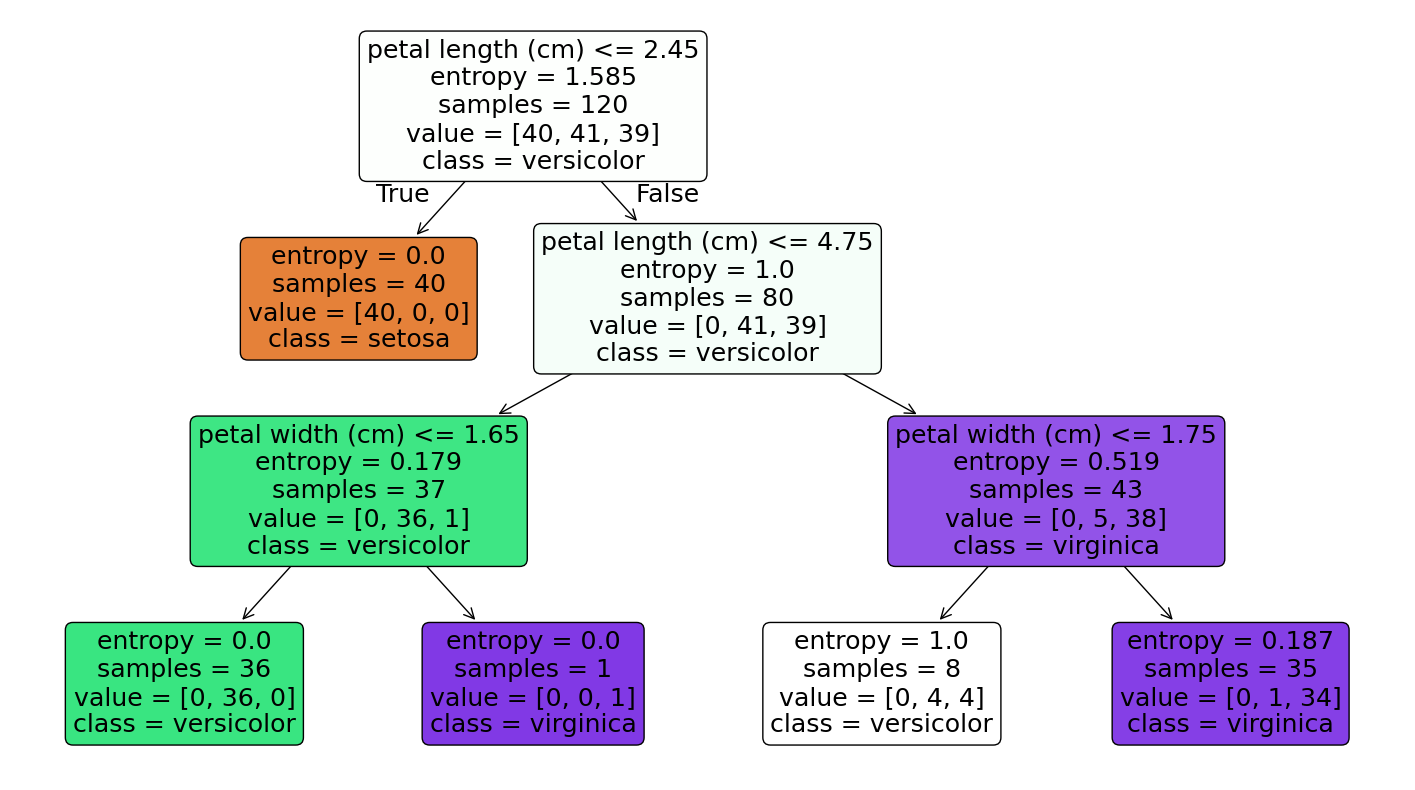

In [ ]:
plt.figure(figsize=(18,10))
plot_tree(dt,feature_names=feature_names,class_names=class_names,filled=True,rounded=True,impurity=True,proportion=False)
plt.show()

In [178]:

print(export_text(dt, feature_names=list(feature_names)))


|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal length (cm) <= 4.75
|   |   |--- petal width (cm) <= 1.65
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.65
|   |   |   |--- class: 2
|   |--- petal length (cm) >  4.75
|   |   |--- petal width (cm) <= 1.75
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.75
|   |   |   |--- class: 2



In [179]:
from sklearn.metrics import classification_report

In [180]:
print(classification_report(y_test,y_pred_dt,target_names=class_names,zero_division=0))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [181]:
from sklearn.metrics import confusion_matrix

In [182]:
cm = confusion_matrix(y_test, y_pred_dt)

In [183]:
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)

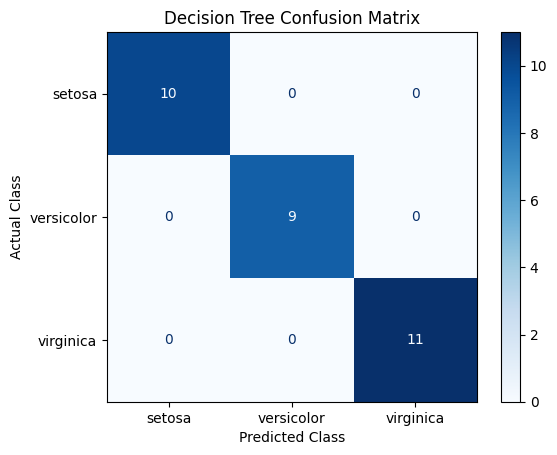

In [184]:
disp.plot(cmap="Blues",values_format="d")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

The Decision Tree classifies samples using threshold-based rules on the four flower measurements. Limiting the depth to three makes the model relatively easy to visualize and interpret. The classification report shows precision, recall, and F1-score for each species, while the confusion matrix identifies correctly and incorrectly classified samples.

In [185]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
depths=range(1,11)
train_accuracy=[]
test_accuracy=[]
for depth in depths:
    model=DecisionTreeClassifier(max_depth=depth,criterion="entropy",random_state=42)
    model.fit(X_train,y_train)
    train_accuracy.append(accuracy_score(y_train, model.predict(X_train)))

    test_accuracy.append(accuracy_score(y_test, model.predict(X_test)))
    

In [186]:
depth_results = pd.DataFrame({
    "Depth": list(depths),
    "Training Accuracy": train_accuracy,
    "Test Accuracy": test_accuracy
})

In [187]:
print(depth_results.to_string(index=False))

 Depth  Training Accuracy  Test Accuracy
     1           0.675000       0.633333
     2           0.950000       0.966667
     3           0.958333       1.000000
     4           0.975000       1.000000
     5           0.991667       1.000000
     6           1.000000       1.000000
     7           1.000000       1.000000
     8           1.000000       1.000000
     9           1.000000       1.000000
    10           1.000000       1.000000


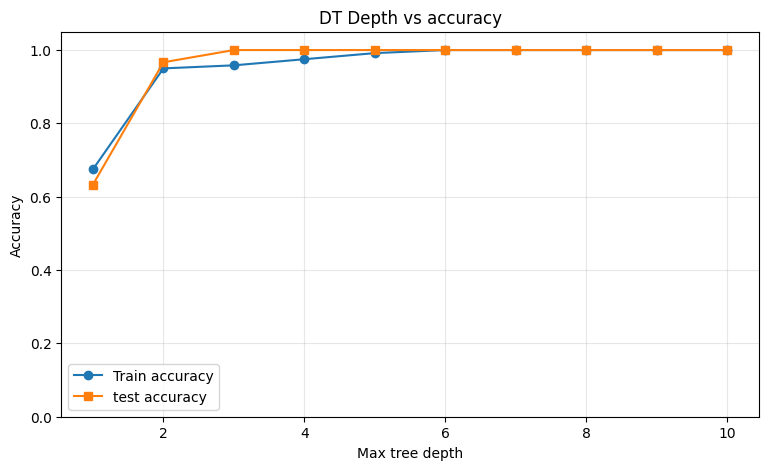

In [188]:
plt.figure(figsize=(9,5))
plt.plot(list(depths),train_accuracy,marker="o",label="Train accuracy")
plt.plot(list(depths),test_accuracy,marker="s",label="test accuracy")
plt.title("DT Depth vs accuracy")
plt.xlabel("Max tree depth")
plt.ylabel("Accuracy")
plt.ylim(0,1.05)
plt.grid(True,alpha=0.3)
plt.legend()
plt.show()


In [189]:
best_d_ind=int(np.argmax(test_accuracy))
best_d=list(depths)[best_d_ind]

In [190]:
print(best_d)
print(best_d_ind)


3
2


As treee depth increase train acuracy generally increase bcz the model can learn more about the decision rules but deep tree can overfit  the data therefore chose depth by considering both test accuracy and complexity of tree

In [191]:
from sklearn.ensemble import RandomForestClassifier

In [192]:
rf=RandomForestClassifier(n_estimators=100,oob_score=True,random_state=42)
rf.fit(X_train,y_train)
y_pred_rf=rf.predict(X_test)
print(rf.oob_score_)
print(accuracy_score(y_test,y_pred_rf))
print(classification_report(y_test,y_pred_rf,target_names=class_names,zero_division=0))

0.9166666666666666
1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [193]:
importance_df=pd.DataFrame({"Feature":feature_names,"Importance":rf.feature_importances_})

          Feature  Importance
petal length (cm)    0.439994
 petal width (cm)    0.421522
sepal length (cm)    0.108098
 sepal width (cm)    0.030387


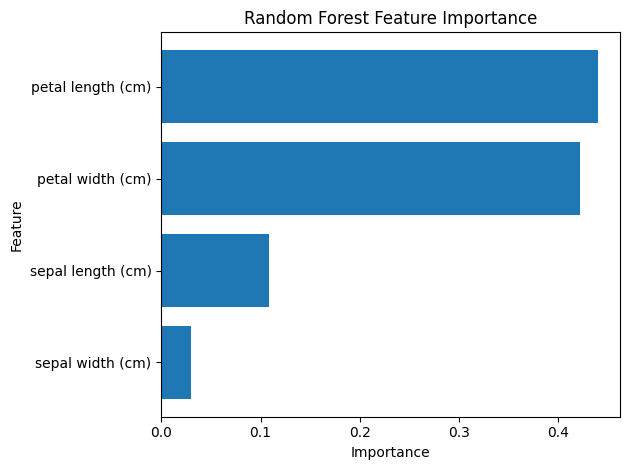

In [194]:
importance_df=importance_df.sort_values(by="Importance",ascending=False)
print(importance_df.to_string(index=False))
plt.Figure(figsize=(9,5))
plt.barh(importance_df["Feature"],importance_df["Importance"]
)
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

the RF combines the prediction from 100 DT it OOB score estimate genralization performance using training sample left out of individual samples.PL AND PW are generally expected to have high feature importance cz they seprate iris species effextively 

In [195]:
param_grid={
    "n_estimators":[50,100,200],
    "max_depth":[None,5,10,15]

}
grid_search=GridSearchCV(estimator=RandomForestClassifier(random_state=42),param_grid=param_grid,cv=5,scoring="accuracy",n_jobs=-1)
grid_search.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of infor

In [196]:
grid_search.fit(X_train,y_train)
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': None, 'n_estimators': 200}
0.95


In [197]:
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

In [198]:
print(accuracy_score(y_test, y_pred_tuned))

1.0


In [199]:
print(classification_report(y_test, y_pred_tuned, target_names=class_names, zero_division=0))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [200]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)


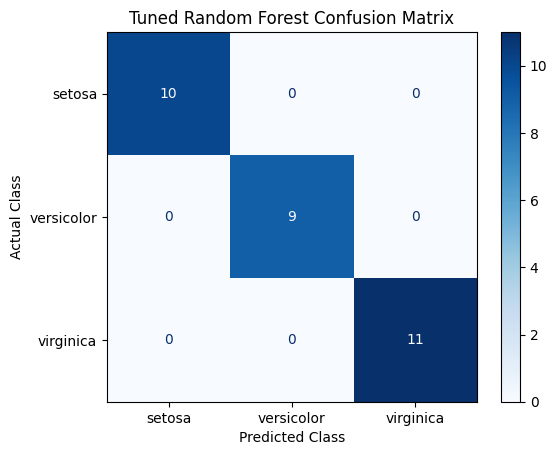

In [201]:
disp = ConfusionMatrixDisplay( confusion_matrix=cm_tuned,display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [202]:
from sklearn.metrics import (classification_report, confusion_matrix,ConfusionMatrixDisplay, accuracy_score,precision_score,recall_score,f1_score)

In [203]:
def get_metrics(y_true, y_pred):
    return {
        "Test Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


comparison = pd.DataFrame(
    [
        get_metrics(y_test, y_pred_dt),
        get_metrics(y_test, y_pred_rf),
        get_metrics(y_test, y_pred_tuned)
    ],
    index=[
        "Decision Tree (depth=3)",
        "Random Forest (default)",
        "Random Forest (tuned)"
    ]
)

print(comparison.round(4))

                         Test Accuracy  Precision  Recall   F1
Decision Tree (depth=3)            1.0        1.0     1.0  1.0
Random Forest (default)            1.0        1.0     1.0  1.0
Random Forest (tuned)              1.0        1.0     1.0  1.0


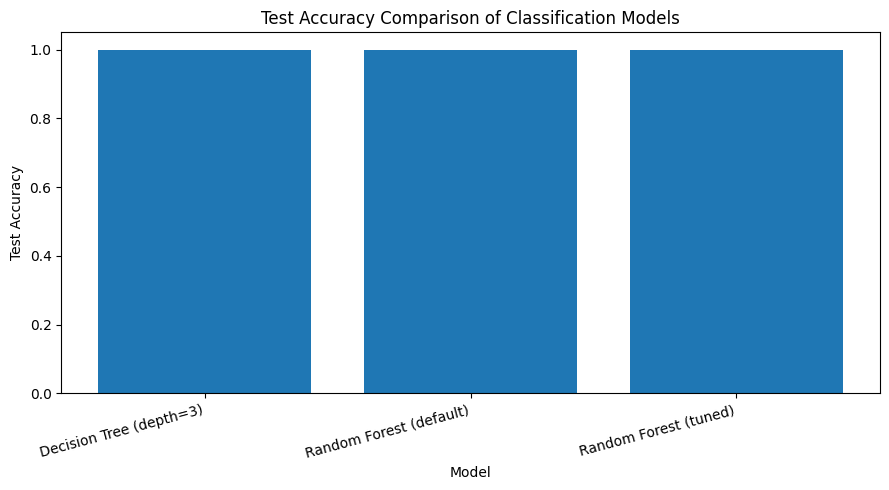

In [204]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison.index,
    comparison["Test Accuracy"]
)

plt.title("Test Accuracy Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()